# Filling missing air-quality data with least squares

Delhi's 39 air-quality monitors, one table of daily AQI (monitors × days, 2017–2023): about **1 in 7** cells is blank.
We fill the blanks with a **low-rank model fitted by alternating least squares**, and test it against four simple
methods on readings we *do* have, hidden on purpose.

1. Data · 2. The gaps · 3. The method · 4. One worked example · 5. 10-fold cross-validation · 6. Filling today

Section 5 takes about 9 minutes on 16 cores. Set `RUN_CV = False` to load the saved results instead.

In [1]:
import glob, os, warnings
warnings.simplefilter('ignore')                  # keep library warnings out of the output
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch
from scipy import sparse
from scipy.sparse.linalg import spsolve
from statsforecast.models import AutoARIMA
from joblib import Parallel, delayed
from tqdm import tqdm

RUN_CV = True                    # False: load results/cv_folds.csv instead of recomputing section 5
F, LAM, GAM = 24, 300, 1000      # f: length of each list;  lambda: ridge penalty;  gamma: smoothness penalty
SITE, GAP = 'r_k_puram_dpcc', ('2023-11-07', '2023-11-13')     # worked example: R K Puram, 4 km from TERI SAS

NAME = dict(carry='carry forward', lin='linear interpolation', arima='auto ARIMA', city='city average', ours='this method')
COL = dict(carry='#C9A227', lin='#E07A18', arima='#9B4DB8', city='#109A7E', ours='#3D5FA6')
rmse = lambda pred, truth: np.sqrt(np.mean((pred - truth) ** 2))
plt.rcParams.update({'font.family': 'serif', 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})

## 1. Data

`data/raw/`: one file per monitor, from [OpenCity's *Delhi Hourly Air Quality Reports*](https://data.opencity.in/dataset/delhi-hourly-air-quality-reports)
(CPCB, DPCC, IMD, IITM). Each month is a block of rows: one row per day, one column per hour.

A day counts only if **at least 16 of its 24 hours** were reported (CPCB's AQI rule). Its value is the mean of those hours, capped at 500.

In [2]:
def read_monitor(path):
    raw = pd.read_csv(path, header=None, names=range(26), dtype=str)
    first = raw[0].str.strip()
    month = first.where(first.str.match(r'^[A-Za-z]+-\d+$', na=False)).ffill()   # "January-2017" heads each month
    day = pd.to_numeric(first, errors='coerce')                                      # day rows start with 1, 2, 3, ...
    rows = raw[day.notna() & month.notna()]
    hours = rows.loc[:, 1:24].apply(lambda c: pd.to_numeric(c.str.strip(), errors='coerce'))
    date = pd.to_datetime(day[rows.index].astype(int).astype(str) + '-' + month[rows.index], format='mixed', dayfirst=True, errors='coerce')
    return pd.DataFrame({'date': date, 'hours': hours.notna().sum(axis=1), 'aqi': hours.mean(axis=1)}).dropna()

daily = {}
for path in tqdm(sorted(glob.glob('data/raw/*.csv')), desc='reading monitors'):
    d = read_monitor(path)
    daily[os.path.basename(path)[:-4]] = d[d.hours >= 16].groupby('date').aqi.mean()     # the 16-hour rule
Y = pd.DataFrame(daily).T.reindex(columns=pd.date_range('2017-01-01', '2023-12-31')).clip(upper=500)
Y.to_csv('data/delhi_daily_aqi.csv')

W = Y.notna().values                                   # True where there is a reading
Y0 = Y.fillna(0).values                                # readings, 0 in the blanks (never used as data)
STN, DAYS = list(Y.index), Y.columns
S, T = W.shape
SPAN = (Y.T.bfill().notna() & Y.T.ffill().notna()).T.values      # each monitor's service period
print(f'{S} monitors x {T} days: {W.sum():,} readings, {(SPAN & ~W).sum():,} blanks = 1 in {SPAN.sum() / (SPAN & ~W).sum():.0f}')

reading monitors: 100%|██████████| 39/39 [00:02<00:00, 16.06it/s]


39 monitors x 2556 days: 73,498 readings, 12,395 blanks = 1 in 7


## 2. The gaps

One row per monitor, one column per day. Red: no reading. Pale: not yet installed. The four monitors within 8 km
of TERI SAS are on top.

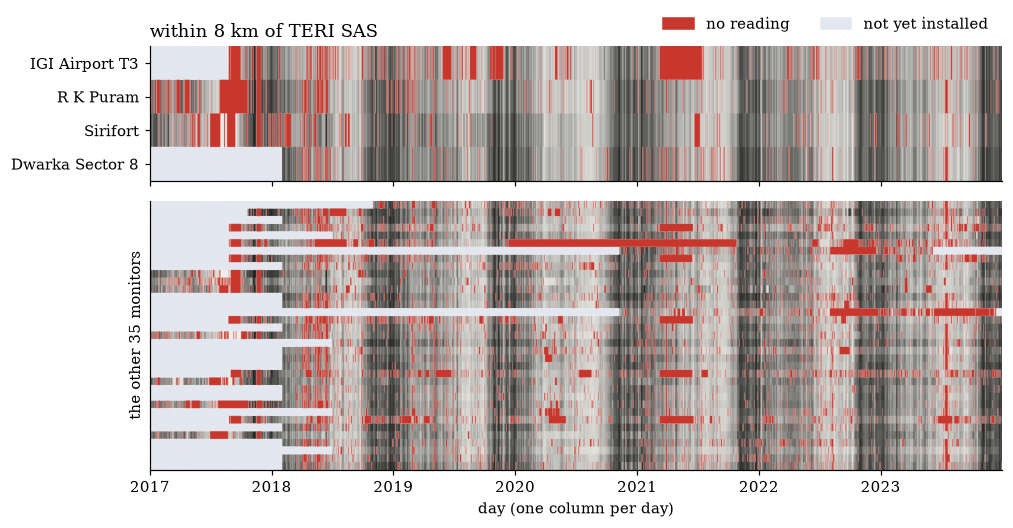

In [3]:
near = pd.read_csv('data/station_coordinates.csv').dropna(subset=['station_id'])      # sorted by distance
groups = [list(near.station_id), [s for s in STN if s not in set(near.station_id)]]      # the four near ones / the rest
status = np.where(W, 0, np.where(SPAN, 1, 2))                                        # reading / blank / not installed

fig, axs = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={'height_ratios': [1, 2], 'hspace': 0.1})
for ax, ids in zip(axs, groups):
    r = np.repeat([STN.index(s) for s in ids], 20)           # each row drawn 20 pixels tall, so rows stay crisp
    box = dict(aspect='auto', extent=(-0.5, T - 0.5, len(ids) - 0.5, -0.5))
    ax.imshow(Y.values[r], cmap=LinearSegmentedColormap.from_list('', ['#f1f0eb', '#1d1d1b']), vmin=0, vmax=500, **box)
    ax.imshow(np.ma.masked_equal(status[r], 0), cmap=ListedColormap(['#C8372D', '#E3E7EF']), vmin=1, vmax=2, **box)
axs[0].set_yticks(range(len(near)), near.place)
axs[0].set_title('within 8 km of TERI SAS', loc='left')
axs[1].set_yticks([]); axs[1].set_ylabel(f'the other {len(groups[1])} monitors')
axs[1].set_xticks([DAYS.get_loc(f'{y}-01-01') for y in range(2017, 2024)], range(2017, 2024))
axs[1].set_xlabel('day (one column per day)')
axs[0].legend(handles=[Patch(color='#C8372D', label='no reading'), Patch(color='#E3E7EF', label='not yet installed')],
              loc='lower right', bbox_to_anchor=(1, 1), ncol=2, frameon=False)
plt.show()

The blanks are not random: monitors miss more of the clean days (monsoon) than the smoggy ones (winter).

In [4]:
pd.DataFrame({'city AQI': Y.mean(axis=0), 'blank %': 100 * (SPAN & ~W).sum(0) / SPAN.sum(0)}).groupby(DAYS.month).mean().round(0).T

,1,2,3,4,5,6,7,8,9,10,11,12
city AQI,307.0,255.0,197.0,205.0,194.0,163.0,101.0,89.0,103.0,243.0,347.0,338.0
blank %,11.0,10.0,14.0,20.0,22.0,17.0,23.0,21.0,22.0,13.0,14.0,8.0


2017 had the most blanks of any year, and they fell on the clean months:

In [5]:
y17 = DAYS.year == 2017
pd.Series({name: 100 * (SPAN & ~W)[:, y17 & DAYS.month.isin(months)].sum() / SPAN[:, y17 & DAYS.month.isin(months)].sum()
           for name, months in [('Jan-Jun', range(1, 7)), ('Jul-Sep, monsoon', [7, 8, 9]), ('Oct-Dec, winter smog', [10, 11, 12])]},
          name='2017: % of monitor-days blank').round(0)

Jan-Jun                 21.0
Jul-Sep, monsoon        67.0
Oct-Dec, winter smog    28.0
Name: 2017: % of monitor-days blank, dtype: float64

## 3. The method

Give each monitor $s$ a list $a_s$ of $f = 24$ numbers and each day $t$ a list $b_t$ of 24 numbers: hidden features,
never observed, learnt from the readings. A reading is their dot product,
$y_{st} \approx a_s^\top b_t$, so $Y_{39\times 2556} \approx A_{39\times 24}\, B^\top_{24\times 2556}$. Choose $A$, $B$ to make

$$L = \underbrace{\sum_{(s,t)\ \text{observed}} (y_{st} - a_s^\top b_t)^2}_{\text{fit the readings}}
+ \underbrace{\lambda \Big(\sum_s \|a_s\|^2 + \sum_t \|b_t\|^2\Big)}_{\text{keep the lists small}}
+ \underbrace{\gamma \sum_t \|b_t - b_{t-1}\|^2}_{\text{the city changes gently}}$$

as small as possible, by **alternating least squares**:

1. Fill $B$ with random numbers.
2. Fix $B$. For each monitor $s$: $y_s$ = its readings, $B_s$ = the rows of $B$ for those days.
   $\partial L / \partial a_s = 0$ gives a ridge regression, $\ \hat a_s = (B_s^\top B_s + \lambda I)^{-1} B_s^\top y_s$.
3. Fix $A$. For each day $t$: $y_t$ = that day's readings, $A_t$ = the rows of $A$ for those monitors.
   $\partial L / \partial b_t = 0$ gives $\ (A_t^\top A_t + \lambda I)\, b_t + \gamma\,(2 b_t - b_{t-1} - b_{t+1}) = A_t^\top y_t$.
   Each day is tied to its neighbours, so the 2,556 equations are solved together.
4. Repeat 2–3 for 40 rounds. Each blank is then $\hat a_s^\top \hat b_t$.

In [6]:
def als_fit(Y0, W, f=F, lam=LAM, gamma=GAM, rounds=40, seed=0, progress=True):
    S, T = W.shape
    I = np.eye(f)
    B = np.sqrt(Y0[W].mean() / f) * (1 + 0.3 * np.random.default_rng(seed).standard_normal((T, f)))   # step 1
    A = np.zeros((S, f))
    D = sparse.diags([np.r_[1, np.full(T - 2, 2), 1], -np.ones(T - 1), -np.ones(T - 1)], [0, -1, 1])   # 2b_t - b_t-1 - b_t+1
    for _ in tqdm(range(rounds), desc='this method: ALS rounds', disable=not progress):
        for s in range(S):                                                      # step 2, one monitor at a time
            B_s, y_s = B[W[s]], Y0[s, W[s]]
            A[s] = np.linalg.solve(B_s.T @ B_s + lam * I, B_s.T @ y_s)
        A_t = [A[W[:, t]] for t in range(T)]                                    # step 3, all days together
        lhs = sparse.block_diag([a.T @ a + lam * I for a in A_t]) + gamma * sparse.kron(D, I)
        rhs = np.concatenate([a.T @ Y0[W[:, t], t] for t, a in enumerate(A_t)])
        B = spsolve(lhs.tocsc(), rhs, permc_spec='NATURAL').reshape(T, f)
    return A, B                                                                 # step 4: blank (s, t) = A[s] @ B[t]

A, B = als_fit(Y0, W)

this method: ALS rounds: 100%|██████████| 40/40 [00:04<00:00,  8.05it/s]


**Why fill the blanks?** Delhi's yearly average AQI over every in-service monitor-day, three ways: from the readings
alone; with each month's readings averaged and then weighted by the month's days in service (no model); and with the
blanks filled by this method. The readings alone read high, because the blanks fall more on clean days: in 2017,
by 20 points even with no model, and by 47 with the blanks filled.

In [7]:
filled = np.where(W, Y0, A @ B.T)

def yearly_means(c):
    m = DAYS.month[c]
    month_means = [Y0[:, c][:, m == k][W[:, c][:, m == k]].mean() for k in range(1, 13)]   # each month's readings
    month_days = [SPAN[:, c][:, m == k].sum() for k in range(1, 13)]                       # each month's days in service
    return {'blank %': 100 * (SPAN & ~W)[:, c].sum() / SPAN[:, c].sum(),
            'readings alone': Y0[:, c][W[:, c]].mean(),
            'months reweighted (no model)': np.average(month_means, weights=month_days),
            'blanks filled': filled[:, c][SPAN[:, c]].mean()}

yearly = pd.DataFrame({yr: yearly_means(DAYS.year == yr) for yr in range(2017, 2024)}).T
yearly['readings - filled'] = yearly['readings alone'] - yearly['blanks filled']
yearly.round(1)

,blank %,readings alone,months reweighted (no model),blanks filled,readings - filled
2017,35.3,244.0,224.0,196.8,47.1
2018,18.1,231.7,226.8,226.5,5.2
2019,11.5,219.9,220.2,218.2,1.8
2020,10.6,192.5,189.9,188.5,4.0
2021,14.7,214.9,212.1,209.4,5.5
2022,13.2,217.3,214.5,212.4,4.9
2023,12.5,213.2,208.0,205.4,7.8


## 4. One worked example: R K Puram, 7–13 Nov 2023

Hide R K Puram's seven readings, fit on everything else, refill, compare. The baselines:

| method | fills monitor $s$, day $t$ with | uses |
|---|---|---|
| carry forward | its last reading before $t$ | its past |
| linear interpolation | a straight line between its readings either side | its past and future |
| auto ARIMA | a model of its own series, predicting each day from the days before it | its past, plus its future through the straight lines |
| city average | the mean of the monitors that reported on day $t$ | the other monitors |

Auto ARIMA is statsforecast's `AutoARIMA`: it picks $(p, d, q)$ by AICc (Hyndman–Khandakar stepwise search; $d$ from a
KPSS test). It needs a complete series, so each monitor's blank and hidden days are first filled by straight lines;
each hidden day is then the model's prediction from the days before it.

In [8]:
def baselines(Y0, W):
    df = pd.DataFrame(np.where(W, Y0, np.nan))
    day_mean = df.mean(axis=0).where(df.notna().any(axis=0))                   # NaN if nobody reported that day
    return {'carry': df.T.ffill().bfill().T.values,
            'lin': df.T.interpolate(limit_direction='both').T.values,
            'city': np.where(day_mean.notna().values[None], day_mean.values[None], df.mean(axis=1).values[:, None]) * np.ones(df.shape)}

def arima_fill(y):                                                              # y: one monitor's series, NaN where blank or hidden
    filled = pd.Series(y).interpolate(limit_direction='both').values            # AutoARIMA needs a complete series: straight lines first
    model = AutoARIMA(season_length=1).fit(filled)                              # (p, d, q) by AICc, stepwise; d by a KPSS test
    return np.clip(model.predict_in_sample()['fitted'], 0, 500), model          # each day predicted from the days before it

In [9]:
s, g = STN.index(SITE), (DAYS >= GAP[0]) & (DAYS <= GAP[1])
Wg = W.copy(); Wg[s, g] = False                                                # hide the week
truth = Y.values[s, g]

fills = {k: v[s, g] for k, v in baselines(Y0, Wg).items()}
A_g, B_g = als_fit(Y0, Wg); fills['ours'] = (A_g @ B_g.T)[s, g]
span = np.flatnonzero(SPAN[s])
arima_pred, arima_model = arima_fill(Y.iloc[s, span].where(Wg[s, span]).values); fills['arima'] = arima_pred[g[span]]

week = pd.DataFrame({NAME[k]: fills[k] for k in NAME}, index=DAYS[g].strftime('%d %b')).T
week.loc['truth'] = truth
week['RMSE'] = [rmse(fills[k], truth) for k in NAME] + [np.nan]
week.round(0)

this method: ALS rounds: 100%|██████████| 40/40 [00:05<00:00,  7.92it/s]


,07 Nov,08 Nov,09 Nov,10 Nov,11 Nov,12 Nov,13 Nov,RMSE
carry forward,444.0,444.0,444.0,444.0,444.0,444.0,444.0,126.0
linear interpolation,440.0,436.0,432.0,429.0,425.0,421.0,418.0,113.0
auto ARIMA,416.0,424.0,419.0,420.0,418.0,417.0,415.0,109.0
city average,412.0,426.0,446.0,227.0,201.0,240.0,388.0,27.0
this method,430.0,443.0,452.0,248.0,227.0,261.0,396.0,14.0
truth,432.0,449.0,459.0,248.0,249.0,273.0,372.0,NaN


The numbers behind each method (last reading before the gap: 6 Nov; first after: 14 Nov):

In [10]:
y, m = Y.iloc[s], arima_model.model_
(p_, q_), d_, c = m['arma'][:2], m['arma'][5], m['coef']
x = 'Δy' if d_ else 'y'                                                          # Δy(t) = y(t) - y(t-1)
eq = ' '.join([f"{c[f'ar{i}']:+.3f} {x}(t-{i})" for i in range(1, p_ + 1)] + [f"{c[f'ma{j}']:+.3f} e(t-{j})" for j in range(1, q_ + 1)])
print(f"carry forward   every hidden day = 6 Nov = {y['2023-11-06']:.1f}")
print(f"linear interp.  7 Nov = {y['2023-11-06']:.1f} + (1/8)({y['2023-11-14']:.1f} - {y['2023-11-06']:.1f}) = {fills['lin'][0]:.1f}")
print(f"auto ARIMA ({p_},{d_},{q_})  {x}(t) = {eq}, e = that day's surprise  ->  7 Nov = {fills['arima'][0]:.1f}")
print(f"city average    10 Nov = mean of the {Wg[:, g][:, 3].sum()} monitors up that day = {fills['city'][3]:.1f}")
print(f"this method     10 Nov = a_s . b_t = {fills['ours'][3]:.1f}   (truth {truth[3]:.1f})")

carry forward   every hidden day = 6 Nov = 443.6
linear interp.  7 Nov = 443.6 + (1/8)(414.0 - 443.6) = 439.9
auto ARIMA (2,1,2)  Δy(t) = +0.100 Δy(t-1) +0.294 Δy(t-2) -0.290 e(t-1) -0.526 e(t-2), e = that day's surprise  ->  7 Nov = 416.4
city average    10 Nov = mean of the 33 monitors up that day = 227.4
this method     10 Nov = a_s . b_t = 248.4   (truth 247.8)


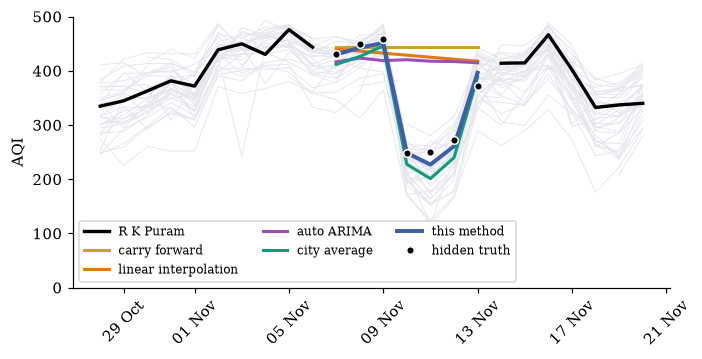

In [11]:
w = (DAYS >= '2023-10-28') & (DAYS <= '2023-11-20')
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(DAYS[w], Y.values[:, w].T, color='#e4e6ec', lw=0.6)                           # the other monitors
ax.plot(DAYS[w], np.where(g[w], np.nan, Y.values[s, w]), color='k', lw=2.2, label='R K Puram')
for k in NAME:
    ax.plot(DAYS[g], fills[k], color=COL[k], lw=2.6 if k == 'ours' else 2, label=NAME[k])
ax.plot(DAYS[g], truth, 'ko', ms=5, mec='w', label='hidden truth')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b')); plt.xticks(rotation=45)
ax.set_ylim(0, 500); ax.set_ylabel('AQI'); ax.legend(ncol=3, fontsize=8, loc='lower left'); plt.show()

Only the last two use the other monitors on the same day, so only they see the dip of 10–12 Nov.

## 5. 10-fold cross-validation

One week is one example. To score on all the data, deal the readings into 10 piles; hide one pile, fit on the other nine,
refill it and score it (RMSE); repeat for each pile. Every reading is scored once; the 10 RMSEs give a mean ± standard error.
Two ways to deal:

* **random days**: the 73,498 readings one by one;
* **random weeks**: 7-day blocks of each monitor's record (week-long gaps).

**Tuning inside each fold.** Take fold 3, whose pile 3 is scored. This method first fits on the other 8 piles once per
setting of $f, \lambda, \gamma$ and keeps the setting that refills pile 4 best; then it refits on all 9 piles with that
setting and refills pile 3. So the scored pile never helps choose the setting. Fold 4 tunes on pile 5, and fold 10 on
pile 1. Settings tried: 27 for this method ($f \in \{8, 16, 24\}$, $\lambda \in \{300, 1000, 3000\}$, $\gamma \in \{100, 1000, 10^4\}$) and 9 for the version without the smooth term ($\gamma = 0$), which shows what the smooth term adds. The baselines have nothing to tune; auto ARIMA picks $(p, d, q)$ by AICc on the 9 piles.

In [12]:
K = 10
def piles(test, seed=2026):
    rng, P = np.random.default_rng(seed), np.full(W.shape, -1)
    if test == 'random days':
        obs = np.flatnonzero(W); P.flat[obs] = rng.permutation(len(obs)) % K
    else:                                                                     # random weeks: deal 7-day blocks
        blocks = [(s, t, min(t + 7, o[-1] + 1)) for s in range(S) for o in [np.flatnonzero(W[s])] for t in range(o[0], o[-1] + 1, 7)]
        for (s, a, b), k in zip(blocks, rng.permutation(len(blocks)) % K):
            P[s, a:b] = k
        P[~W] = -1
    return P
PILES = {test: piles(test) for test in ('random days', 'random weeks')}

GRID = [(f, l, g_) for f in (8, 16, 24) for l in (300, 1000, 3000) for g_ in (100, 1000, 10000)]   # f, lambda, gamma
GRID0 = [(f, l, 0.0) for f in (8, 16, 24) for l in (300, 1000, 3000)]                              # no smooth term

FOLDS = [(test, k) for test in PILES for k in range(K)]                         # 2 tests x 10 folds
def masks(test, k):                                                             # scored pile, what the methods see, tuning pile
    hide = PILES[test] == k
    return hide, W & ~hide, PILES[test] == (k + 1) % K

def run(desc, job, jobs):                                                       # run jobs in parallel behind one progress bar
    out, bar = {}, tqdm(total=len(jobs), desc=desc)
    for key, value in Parallel(n_jobs=-1, return_as='generator_unordered')(delayed(job)(*j) for j in jobs):
        out[key] = value
        bar.set_postfix_str(f'{key[0]}, fold {key[1] + 1} of {K}'); bar.update()
    bar.close()
    return out

def arima_job(test, k, s):                                                      # auto ARIMA, one monitor, one fold
    warnings.simplefilter('ignore')                                             # (jobs run in separate worker processes)
    hide, seen, _ = masks(test, k)
    span, row = np.flatnonzero(SPAN[s]), np.zeros(T)
    if hide[s, span].any(): row[span] = arima_fill(np.where(seen[s, span], Y0[s, span], np.nan))[0]
    return (test, k, s), row

def als_job(test, k, setting, final):                                           # this method, one setting, one fold
    warnings.simplefilter('ignore')
    hide, seen, tune = masks(test, k)
    if final:                                                                   # fit on the nine piles, refill the hidden one
        A_, B_ = als_fit(Y0, seen, *setting, progress=False)
        return (test, k, setting), np.clip(A_ @ B_.T, 0, 500)[hide]
    A_, B_ = als_fit(Y0, seen & ~tune, *setting, progress=False)                # tuning: leave out the next pile too, score on it
    return (test, k, setting), rmse((A_ @ B_.T)[tune], Y0[tune])

OURS = {'this method': GRID, 'this method, no smooth term': GRID0}
if RUN_CV:
    pred, bar = {}, tqdm(FOLDS, desc='carry forward, linear interpolation, city average')
    for test, k in bar:
        bar.set_postfix_str(f'{test}, fold {k + 1} of {K}')
        hide, seen, _ = masks(test, k)
        pred[test, k] = {NAME[m]: v[hide] for m, v in baselines(Y0, seen).items()}
    arima = run(f'auto ARIMA ({S} monitors x {len(PILES)} tests x {K} folds)', arima_job, [(t, k, s) for t, k in FOLDS for s in range(S)])
    tuning = run(f'this method, tuning ({len(GRID)} + {len(GRID0)} settings x {len(PILES)} tests x {K} folds)', als_job,
                 [(t, k, x, False) for t, k in FOLDS for x in GRID + GRID0])
    best = {(t, k, name): min(grid, key=lambda x: tuning[t, k, x]) for t, k in FOLDS for name, grid in OURS.items()}
    final = run(f'this method, final fits (with and without smooth term x {len(PILES)} tests x {K} folds)', als_job, [(t, k, best[t, k, n], True) for t, k in FOLDS for n in OURS])
    rows = []
    for t, k in FOLDS:
        hide = masks(t, k)[0]
        pred[t, k][NAME['arima']] = np.array([arima[t, k, s] for s in range(S)])[hide]
        pred[t, k].update({n: final[t, k, best[t, k, n]] for n in OURS})
        rows += [dict(test=t, fold=k, method=m, rmse=rmse(v, Y0[hide])) for m, v in pred[t, k].items()]
    cv = pd.DataFrame(rows)
    os.makedirs('results', exist_ok=True); cv.to_csv('results/cv_folds.csv', index=False)
else:
    cv = pd.read_csv('results/cv_folds.csv')

table = cv.groupby(['method', 'test']).rmse.agg(RMSE='mean', SE=lambda r: r.std() / np.sqrt(K)).unstack('test').round(1)
table.loc[[NAME[m] for m in ('carry', 'lin', 'arima', 'city')] + ['this method, no smooth term', 'this method']]

carry forward, linear interpolation, city average: 100%|██████████| 20/20 [00:00<00:00, 126.98it/s, random weeks, fold 10 of 10]
auto ARIMA (39 monitors x 2 tests x 10 folds): 100%|██████████| 780/780 [01:37<00:00,  8.02it/s, random weeks, fold 10 of 10]
this method, tuning (27 + 9 settings x 2 tests x 10 folds): 100%|██████████| 720/720 [05:16<00:00,  2.27it/s, random weeks, fold 10 of 10]
this method, final fits (with and without smooth term x 2 tests x 10 folds): 100%|██████████| 40/40 [00:24<00:00,  1.63it/s, random weeks, fold 10 of 10]


RMSE                       SE             
test                        random days random weeks random days random weeks
method                                                                       
carry forward                      57.3         79.9         0.2          0.5
linear interpolation               43.1         64.9         0.1          0.3
auto ARIMA                         50.9         63.2         0.2          0.2
city average                       40.0         40.0         0.2          0.2
this method, no smooth term        31.4         31.7         0.2          0.3
this method                        24.1         29.0         0.2          0.3

Carry forward, linear interpolation and auto ARIMA look only along one monitor's own series, so they cannot see what
the rest of the city did that day. The city average sees the other monitors but ignores each monitor's own level.
This method uses both; the smooth term matters most when whole weeks are missing.

## 6. Filling today

Fit once on 2017–2022 and keep $A$. Each new day, only $b_t$ is unknown: one ridge regression on that day's readings,
pulled towards yesterday's list: $\hat b_t = (A_t^\top A_t + (\lambda+\gamma) I)^{-1}(A_t^\top y_t + \gamma\, \hat b_{t-1})$.
A monitor that is down today gets $\hat a_s^\top \hat b_t$; nothing from tomorrow is used.
Test: week-long gaps hidden in 2023 (10% of 2023's readings, two random draws).

In [13]:
past, test = DAYS.year <= 2022, DAYS.year == 2023
A_p, B_p = als_fit(Y0[:, past], W[:, past])

def fill_today(Y0, W, b):
    out = []
    for t in range(Y0.shape[1]):
        A_t, y_t = A_p[W[:, t]], Y0[W[:, t], t]
        b = np.linalg.solve(A_t.T @ A_t + (LAM + GAM) * np.eye(F), A_t.T @ y_t + GAM * b)
        out.append(A_p @ b)
    return np.array(out).T

result = []
for seed in tqdm((0, 1), desc='2023 test, one per random draw of gaps'):
    rng, hide = np.random.default_rng(100 + seed), np.zeros_like(W)
    while (hide & W & test).sum() < 0.1 * (W & test).sum():
        s_ = rng.integers(S); ok = np.flatnonzero(SPAN[s_] & test)
        if len(ok): t0 = rng.choice(ok); hide[s_, t0:t0 + 7] = True
    hide &= W & test; Wo = W & ~hide; h = hide[:, test]; truth23 = Y0[:, test][h]
    result.append({NAME['carry']: rmse(baselines(Y0, Wo)['carry'][:, test][h], truth23),
                   NAME['city']: rmse(baselines(Y0[:, test], Wo[:, test])['city'][h], truth23),
                   'this method, today': rmse(fill_today(Y0[:, test], Wo[:, test], B_p[-1])[h], truth23)})
pd.DataFrame(result).mean().round(0).rename('RMSE, 2023 week-long gaps').to_frame()

2023 test, one per random draw of gaps: 100%|██████████| 2/2 [00:00<00:00, 25.72it/s]


,"RMSE, 2023 week-long gaps"
carry forward,70.0
city average,42.0
"this method, today",31.0


---
Data: OpenCity, *Delhi Hourly Air Quality Reports* (CPCB, DPCC, IMD, IITM). Day rule: CPCB National Air Quality Index
report. Monitor coordinates: Miinalainen et al. (2022), supplement to ACP discussion paper acp-2022-513, Table S1;
campus pin from the TERI SAS contact page.